# Zero initialization — does GD still build the circuit?

`train_with_zero_initialization.py` runs the folder-17 setup with one change: $W_{qk}$ for both
layers starts at **exactly zero** instead of $\mathcal{N}(0,1/\sqrt{\text{fan-in}})$. Everything
else is byte-identical — same frozen $W_{ov}$, same identity-selector unembedding, same direct
`log(f + b)` readout, same lr / batch / epochs, same seed, same batch order.

This notebook puts that run next to its random-init twin,
`wqkevo_opt-adam_lr-0.005_b-256_init-normal_ep-1000`, and asks three things:

1. **Does it train at all?** Zero is the maximally symmetric start — no random asymmetry to
   amplify.
2. **Does it reach the same loss?** Same endpoint, or a different basin.
3. **Does it find the same structure?** Same blocks, same induction diagonal, same energy inside
   the construction's support.

### One thing to know before reading epoch 1

At $W_{qk}=0$ the **layer-1 gradient is exactly zero**. Not small — zero. Layer 1's output can
reach the loss by two routes and at step 0 both are closed: $W_{ov}^{(2)}$ reads rows $0{:}8$ (the
position's own token), never rows $108{:}116$, so layer 1 is not in the value path; and
$W_{qk}^{(2)}=0$ means it contributes nothing to any score either.

It unlocks after **one** optimizer step, as soon as $W_{qk}^{(2)}\neq0$:

| step | 0 | 1 | 2 | 5 |
|---|---|---|---|---|
| $\|g_1\|$ | **0.00e+00** | 1.66e-06 | 3.42e-06 | 8.05e-06 |

(random init has 1.18e-05 already at step 0). So rows 0 and 1 of the layer-1 snapshots are
identical *by construction*. That is expected, not a bug.


In [1]:
import os, glob, json, math
import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm

V, VS, T = 8, 4, 100
D, IN2 = V + T, 2 * (V + T)
SD = D ** 0.5
ALPHA_REC, GAMMA, P1, P2, NF, BIG = 20.0, -50000.0, 1000.0, 50.0, 10.0, -1e9

# ---- the construction, as the reference target ----------------------------------------
Wq1 = torch.eye(D) * SD
T1 = torch.zeros(D, D)
for k in range(VS, V):
    T1[k, :] = BIG
for tq in range(T):
    for tk in range(T):
        T1[V + tk, V + tq] = BIG if tq == tk else -ALPHA_REC * (tq - tk)
Wq2 = torch.zeros(D, IN2)
Wq2[:VS, :VS] = torch.eye(VS) * SD * P1
Wq2[:VS, D:D + VS] = torch.eye(VS) * SD * P2
for v in range(V):
    Wq2[VS, v] = SD * NF
Wk2 = torch.zeros(D, IN2)
Wk2[:V, D:D + V] = torch.eye(V)
for v in range(VS, V):
    Wk2[VS, v] = GAMMA
CQK = [(Wq1.t() @ T1.t()), (Wq2.t() @ Wk2)]

# the construction's non-zero support, per layer
MASK = [np.zeros((D, D), bool), np.zeros((IN2, IN2), bool)]
MASK[0][:, VS:V] = True; MASK[0][V:D, V:D] = True
MASK[1][0:V, 0:V] = True; MASK[1][0:V, D:D + V] = True; MASK[1][D:D + V, D:D + V] = True
for li in (0, 1):
    nz = (CQK[li].numpy() != 0)
    print(f'W_qk layer{li+1}: construction nnz {nz.sum():6d}  support {MASK[li].sum():6d}/'
          f'{MASK[li].size} ({MASK[li].sum()/MASK[li].size:.2%})  all nnz inside: '
          f'{bool((nz & ~MASK[li]).sum() == 0)}')

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 140, 'font.size': 11, 'axes.grid': False})
FIGDIR = 'artifacts/figures_zero'
os.makedirs(FIGDIR, exist_ok=True)

def diag_off(block, n=VS):
    s = np.asarray(block)[:n, :n]
    dg = np.abs(np.diag(s)).mean()
    of = np.abs(s - np.diag(np.diag(s))).sum() / (s.size - n)
    return dg / of if of > 1e-30 else float('inf')

def share(A, mask):
    A = np.asarray(A, dtype=np.float64); tot = float((A ** 2).sum())
    return float((A[mask] ** 2).sum() / tot) if tot > 0 else float('nan')

def cos(A, B):
    a = torch.as_tensor(np.asarray(A)).flatten().double()
    b = torch.as_tensor(np.asarray(B)).flatten().double()
    return float(a @ b / (a.norm() * b.norm() + 1e-30))


W_qk layer1: construction nnz  10432  support  10432/11664 (89.44%)  all nnz inside: True
W_qk layer2: construction nnz     48  support    192/46656 (0.41%)  all nnz inside: True


## 1. Loading both runs

`RUNS` maps a short label to its cell tag. Both were produced by scripts that differ only in
`apply_init`, so any difference below is attributable to the initialization alone.


In [2]:
import importlib.util
RUNS = {'zero':   'wqkzero_opt-adam_lr-0.005_b-256_init-zeros_ep-1000',
        'normal': 'wqkevo_opt-adam_lr-0.005_b-256_init-normal_ep-1000'}
THRS  = [0.6, 0.8, 1.0]
WHICH = 'final'                      # 'final' or 'best'

_s = importlib.util.spec_from_file_location('z', 'train_with_zero_initialization.py')
ZI = importlib.util.module_from_spec(_s); _s.loader.exec_module(ZI)

MET, SNAP, SMETA, QK = {}, {}, {}, {}
missing = []
for lab, cell in RUNS.items():
    rdir, adir = os.path.join('runs', cell), os.path.join('artifacts', cell)
    for t in THRS:
        mp = os.path.join(rdir, f'metrics_combined_seed0_x_{t}.json')
        if not os.path.exists(mp):
            missing.append(mp); continue
        MET[(lab, t)] = json.load(open(mp))
        n = json.load(open(os.path.join(adir, f'snapmeta_x_{t}.json')))['rows_written']
        SMETA[(lab, t)] = json.load(open(os.path.join(adir, f'snapmeta_x_{t}.json')))
        SNAP[(lab, t)] = [np.load(os.path.join(adir, f'wqk1_x_{t}.npy'), mmap_mode='r')[:n],
                          np.load(os.path.join(adir, f'wqk2_x_{t}.npy'), mmap_mode='r')[:n]]
        m = ZI.QKOnlyTransformer(V, T, D, VS, t)
        m.load_state_dict(torch.load(os.path.join(rdir,
                          f'model_{WHICH}_combined_seed0_x_{t}.pth'),
                          map_location='cpu', weights_only=True))
        QK[(lab, t)] = [m.layer1.W_qk.detach(), m.layer2.W_qk.detach()]
if missing:
    raise FileNotFoundError('run the training first; missing:\n  ' + '\n  '.join(missing))

print(f'{"run":8s} {"alpha":>6s} {"init tr":>9s} {"init te":>9s} {"final tr":>9s} '
      f'{"final te":>9s} {"best te":>9s} {"snaps":>6s} {"min":>7s}')
for lab in RUNS:
    for t in THRS:
        m = MET[(lab, t)]; h = m['history']
        print(f'{lab:8s} {t:6.1f} {h["train_loss"][0]:9.4f} {h["test_loss"][0]:9.4f} '
              f'{m["final_train"]:9.4f} {m["final_test"]:9.4f} {m["best_test"]:9.4f} '
              f'{m["snapshots"]["rows_written"]:6d} {m["time_s"]/60:6.1f}')
    print()

print('zero-init sanity: row 0 of every snapshot must be exactly 0')
for t in THRS:
    a = np.abs(np.asarray(SNAP[('zero', t)][0][0])).max()
    b = np.abs(np.asarray(SNAP[('zero', t)][1][0])).max()
    same01 = np.array_equal(np.asarray(SNAP[('zero', t)][0][0]),
                            np.asarray(SNAP[('zero', t)][0][1]))
    print(f'  alpha={t}: |W_qk1(0)|max={a:.3g}  |W_qk2(0)|max={b:.3g}  '
          f'row0 == row1 for layer 1 (the one-step freeze): {same01}')


run       alpha   init tr   init te  final tr  final te   best te  snaps     min
zero        0.6    2.0416    2.0410    1.6894    1.6960    1.6960   1001    8.5
zero        0.8    1.7646    1.7626    1.3858    1.3929    1.3927   1001    8.5
zero        1.0    1.1491    1.1522    0.7475    0.7544    0.7544   1001    8.5

normal      0.6    2.0413    2.0407    1.6894    1.6960    1.6960   1001    8.8
normal      0.8    1.7646    1.7626    1.3859    1.3930    1.3927   1001    8.7
normal      1.0    1.1492    1.1523    0.7475    0.7543    0.7543   1001    8.7

zero-init sanity: row 0 of every snapshot must be exactly 0
  alpha=0.6: |W_qk1(0)|max=0  |W_qk2(0)|max=0  row0 == row1 for layer 1 (the one-step freeze): False
  alpha=0.8: |W_qk1(0)|max=0  |W_qk2(0)|max=0  row0 == row1 for layer 1 (the one-step freeze): False
  alpha=1.0: |W_qk1(0)|max=0  |W_qk2(0)|max=0  row0 == row1 for layer 1 (the one-step freeze): False


/home/hariguru/miniconda3/envs/ashu_env/lib/python3.11/site-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


## 2. Do the two initializations reach the same loss?

The headline question. If the curves land on top of each other, the zero start costs nothing and
the solution is not an artefact of the random draw. If they separate, the initialization selects
the basin.


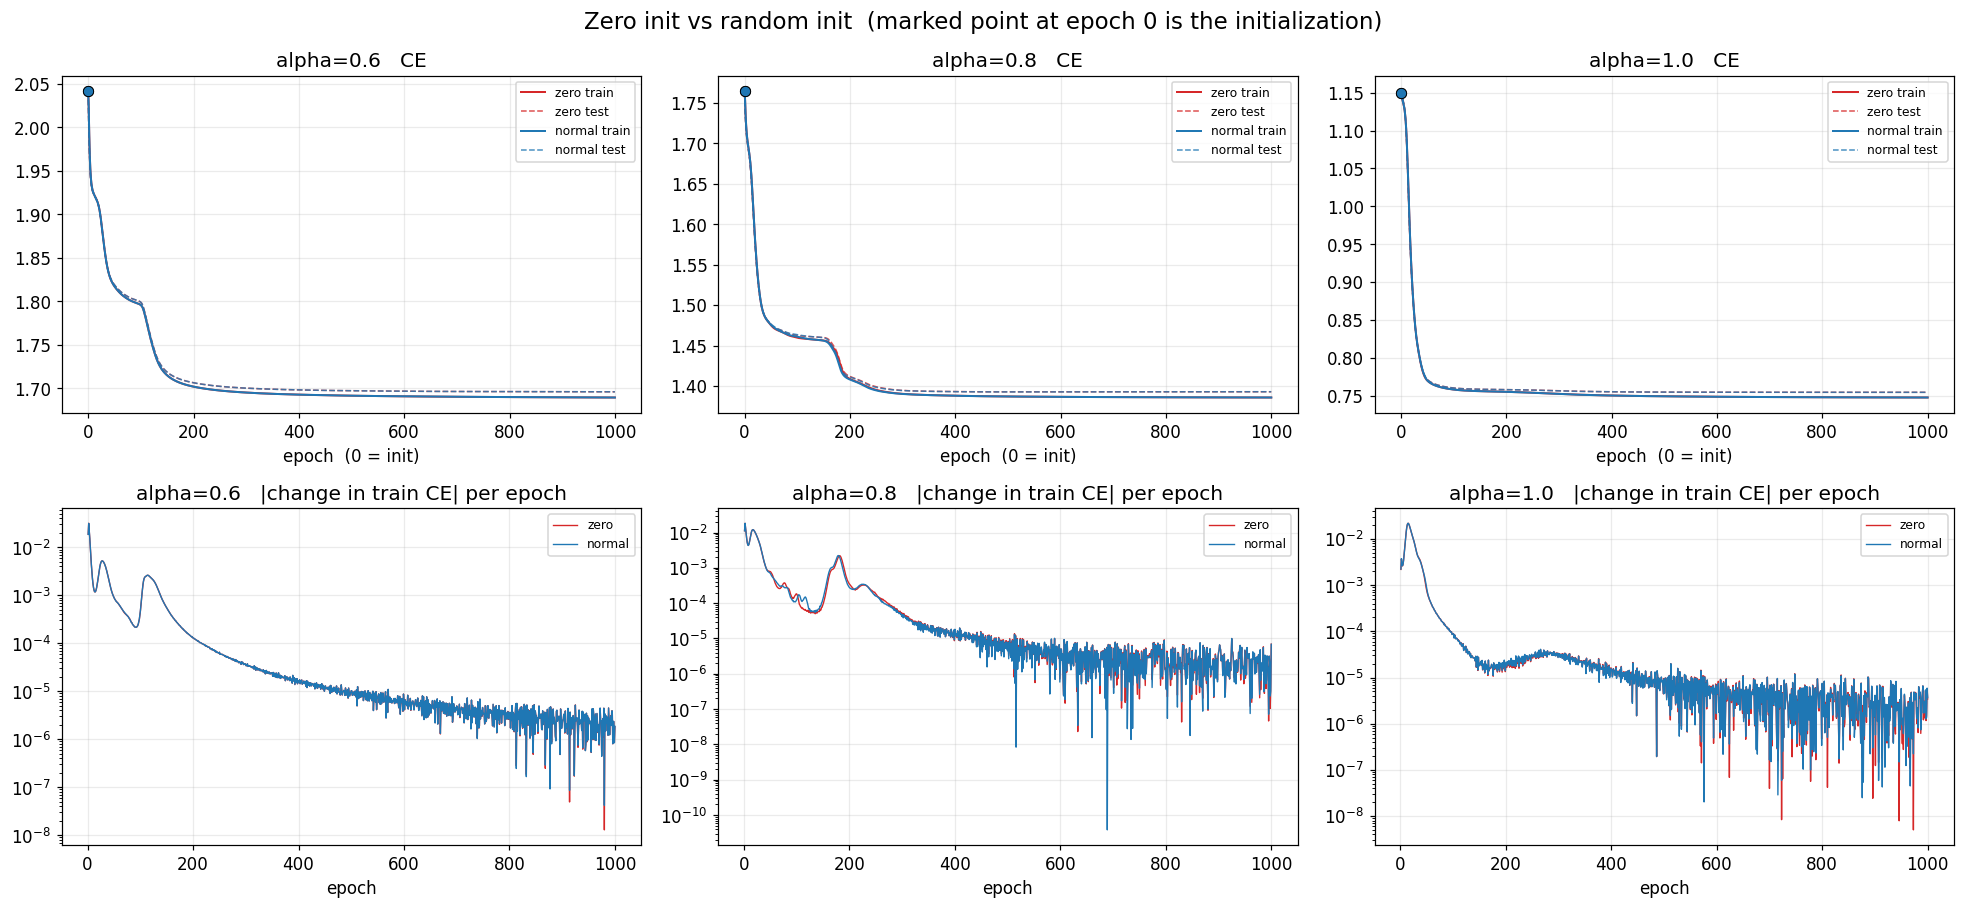

 alpha  zero final te  normal final te        gap  zero best te  normal best te
   0.6         1.6960           1.6960    +0.0000        1.6960          1.6960
   0.8         1.3929           1.3930    -0.0001        1.3927          1.3927
   1.0         0.7544           0.7543    +0.0000        0.7544          0.7543


In [3]:
COL = {'zero': '#d62728', 'normal': '#1f77b4'}
fig, axes = plt.subplots(2, len(THRS), figsize=(6.0 * len(THRS), 8.4))
for j, t in enumerate(THRS):
    for lab in RUNS:
        h = MET[(lab, t)]['history']
        axes[0][j].plot(h['epoch'], h['train_loss'], color=COL[lab], lw=1.3, label=f'{lab} train')
        axes[0][j].plot(h['epoch'], h['test_loss'], color=COL[lab], lw=1.0, ls='--', alpha=0.8,
                        label=f'{lab} test')
        axes[1][j].plot(h['epoch'][1:], np.abs(np.diff(h['train_loss'])), color=COL[lab], lw=0.9,
                        label=lab)
        axes[0][j].scatter([0], [h['train_loss'][0]], color=COL[lab], s=45, zorder=5,
                           edgecolor='k', linewidth=0.6)
    axes[0][j].set_title(f'alpha={t}   CE'); axes[0][j].set_xlabel('epoch  (0 = init)')
    axes[0][j].grid(alpha=0.25); axes[0][j].legend(fontsize=8)
    axes[1][j].set_yscale('log'); axes[1][j].set_xlabel('epoch')
    axes[1][j].set_title(f'alpha={t}   |change in train CE| per epoch')
    axes[1][j].grid(alpha=0.25); axes[1][j].legend(fontsize=8)
fig.suptitle('Zero init vs random init  (marked point at epoch 0 is the initialization)',
             fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'ce_zero_vs_normal.png'), bbox_inches='tight')
plt.show()

print(f'{"alpha":>6s} {"zero final te":>14s} {"normal final te":>16s} {"gap":>10s} '
      f'{"zero best te":>13s} {"normal best te":>15s}')
for t in THRS:
    z, n = MET[('zero', t)], MET[('normal', t)]
    print(f'{t:6.1f} {z["final_test"]:14.4f} {n["final_test"]:16.4f} '
          f'{z["final_test"]-n["final_test"]:+10.4f} {z["best_test"]:13.4f} '
          f'{n["best_test"]:15.4f}')


## 3. Norm growth and the induction block

Zero init has to grow the matrices from nothing, so $\|W_{qk}\|$ starting at $0$ rather than
$\approx10.4$ / $14.7$ is expected. What matters is whether the curves **converge to the same
level** and whether the induction diagonal forms at the same time.


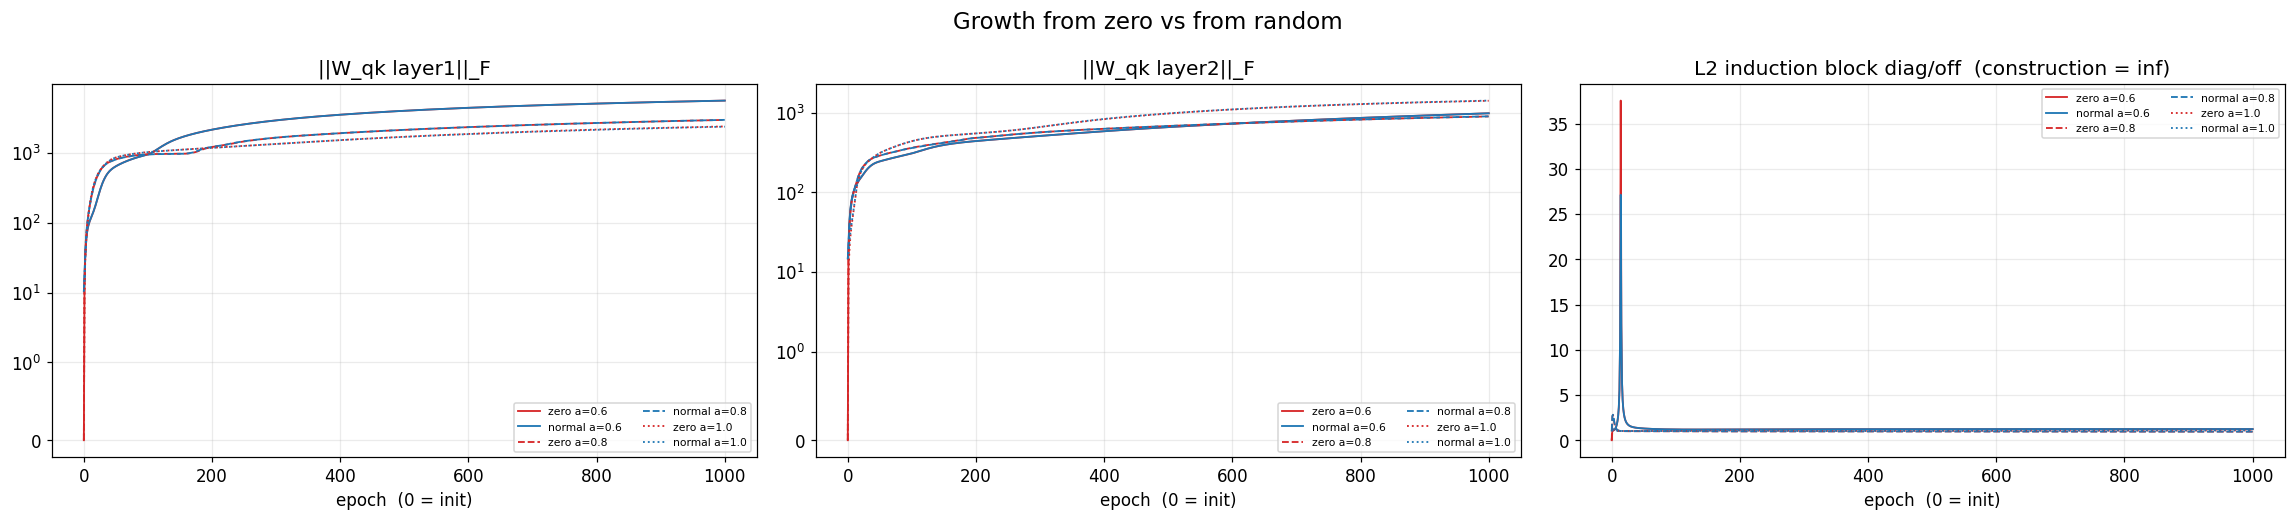

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(21, 4.8))
for t in THRS:
    ls = {0.6: '-', 0.8: '--', 1.0: ':'}[t]
    for lab in RUNS:
        h = MET[(lab, t)]['history']
        axes[0].plot(h['epoch'], h['wqk1_fro'], color=COL[lab], ls=ls, lw=1.2,
                     label=f'{lab} a={t}')
        axes[1].plot(h['epoch'], h['wqk2_fro'], color=COL[lab], ls=ls, lw=1.2,
                     label=f'{lab} a={t}')
        axes[2].plot(h['epoch'], h['induction_diag_off'], color=COL[lab], ls=ls, lw=1.2,
                     label=f'{lab} a={t}')
for i, ttl in enumerate(['||W_qk layer1||_F', '||W_qk layer2||_F',
                         'L2 induction block diag/off  (construction = inf)']):
    axes[i].set_xlabel('epoch  (0 = init)'); axes[i].set_title(ttl)
    axes[i].grid(alpha=0.25); axes[i].legend(fontsize=7, ncol=2)
    if i < 2:
        axes[i].set_yscale('symlog', linthresh=1.0)
fig.suptitle('Growth from zero vs from random', fontsize=15)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'norms_zero_vs_normal.png'), bbox_inches='tight')
plt.show()


## 4. Does the energy land in the construction's support?

The sharpest structural test. Layer 2's support is 192 cells out of 46,656 — **0.41%**. If a
matrix spread its mass uniformly, that is the share it would hold. At the random init the
*gradient* already sat at 0.48–0.89 there while the parameters were at the uniform baseline; the
zero init starts with no parameter mass at all, so this plot shows where GD chooses to put it.


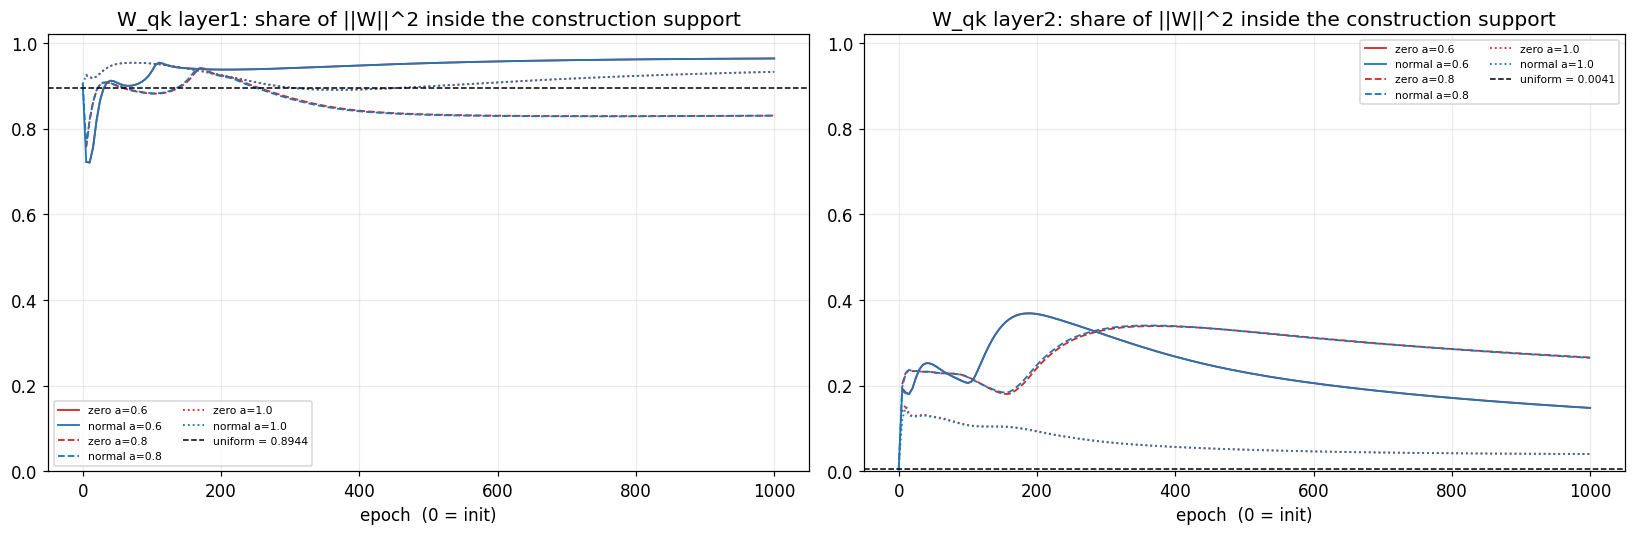

 alpha run       L1 support  L2 support   ind d/o  cos Wqk2 vs constr  |Wqk2|/constr
   0.6 zero          0.9640      0.1479      1.23               0.169       3.33e-05
   0.6 normal        0.9639      0.1476      1.23               0.169       3.33e-05
       uniform       0.8944      0.0041

   0.8 zero          0.8305      0.2655      0.95               0.181       3.04e-05
   0.8 normal        0.8303      0.2648      0.95               0.181       3.05e-05
       uniform       0.8944      0.0041

   1.0 zero          0.9327      0.0402      1.09               0.000       4.78e-05
   1.0 normal        0.9327      0.0400      1.10               0.000       4.81e-05
       uniform       0.8944      0.0041



In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
base = [MASK[0].sum() / MASK[0].size, MASK[1].sum() / MASK[1].size]
for li, ax in enumerate(axes):
    for t in THRS:
        ls = {0.6: '-', 0.8: '--', 1.0: ':'}[t]
        for lab in RUNS:
            A = SNAP[(lab, t)][li]
            ep = SMETA[(lab, t)]['epochs']
            step = max(1, len(ep) // 200)
            xs = list(range(0, len(ep), step))
            ax.plot([ep[i] for i in xs], [share(A[i], MASK[li]) for i in xs],
                    color=COL[lab], ls=ls, lw=1.2, label=f'{lab} a={t}')
    ax.axhline(base[li], color='k', ls='--', lw=1.0, label=f'uniform = {base[li]:.4f}')
    ax.set_xlabel('epoch  (0 = init)'); ax.set_ylim(0, 1.02)
    ax.set_title(f'W_qk layer{li+1}: share of ||W||^2 inside the construction support')
    ax.grid(alpha=0.25); ax.legend(fontsize=7, ncol=2)
fig.tight_layout()
fig.savefig(os.path.join(FIGDIR, 'support_share_zero_vs_normal.png'), bbox_inches='tight')
plt.show()

print(f'{"alpha":>6s} {"run":8s} {"L1 support":>11s} {"L2 support":>11s} {"ind d/o":>9s} '
      f'{"cos Wqk2 vs constr":>19s} {"|Wqk2|/constr":>14s}')
for t in THRS:
    for lab in RUNS:
        q = QK[(lab, t)]
        print(f'{t:6.1f} {lab:8s} {share(q[0], MASK[0]):11.4f} {share(q[1], MASK[1]):11.4f} '
              f'{diag_off(np.asarray(q[1])[:V, D:D+V]):9.2f} '
              f'{cos(q[1], CQK[1]):19.3f} '
              f'{float(q[1].norm()/CQK[1].norm()):14.3g}')
    print(f'{"":6s} {"uniform":8s} {base[0]:11.4f} {base[1]:11.4f}')
    print()


## 5. Are the two solutions the same matrix?

Beyond reaching the same loss, do they reach the same *point*? Cosine similarity between the two
runs' final $W_{qk}$, and between each and the construction. Remember $W_{qk}$ carries a
temperature gauge, so a cosine near 1 with different norms still means "the same solution".


 alpha  layer   cos(zero, normal)   cos(zero, constr)   cos(normal, constr)  |zero|/|normal|
   0.6      1              1.0000              0.2911                0.2912            1.000
   0.6      2              0.9996              0.1689                0.1686            1.000

   0.8      1              0.9996              0.1116                0.1112            0.999
   0.8      2              0.9982              0.1808                0.1815            0.998

   1.0      1              0.9979              0.0339                0.0334            1.008
   1.0      2              0.9972              0.0001                0.0001            0.995



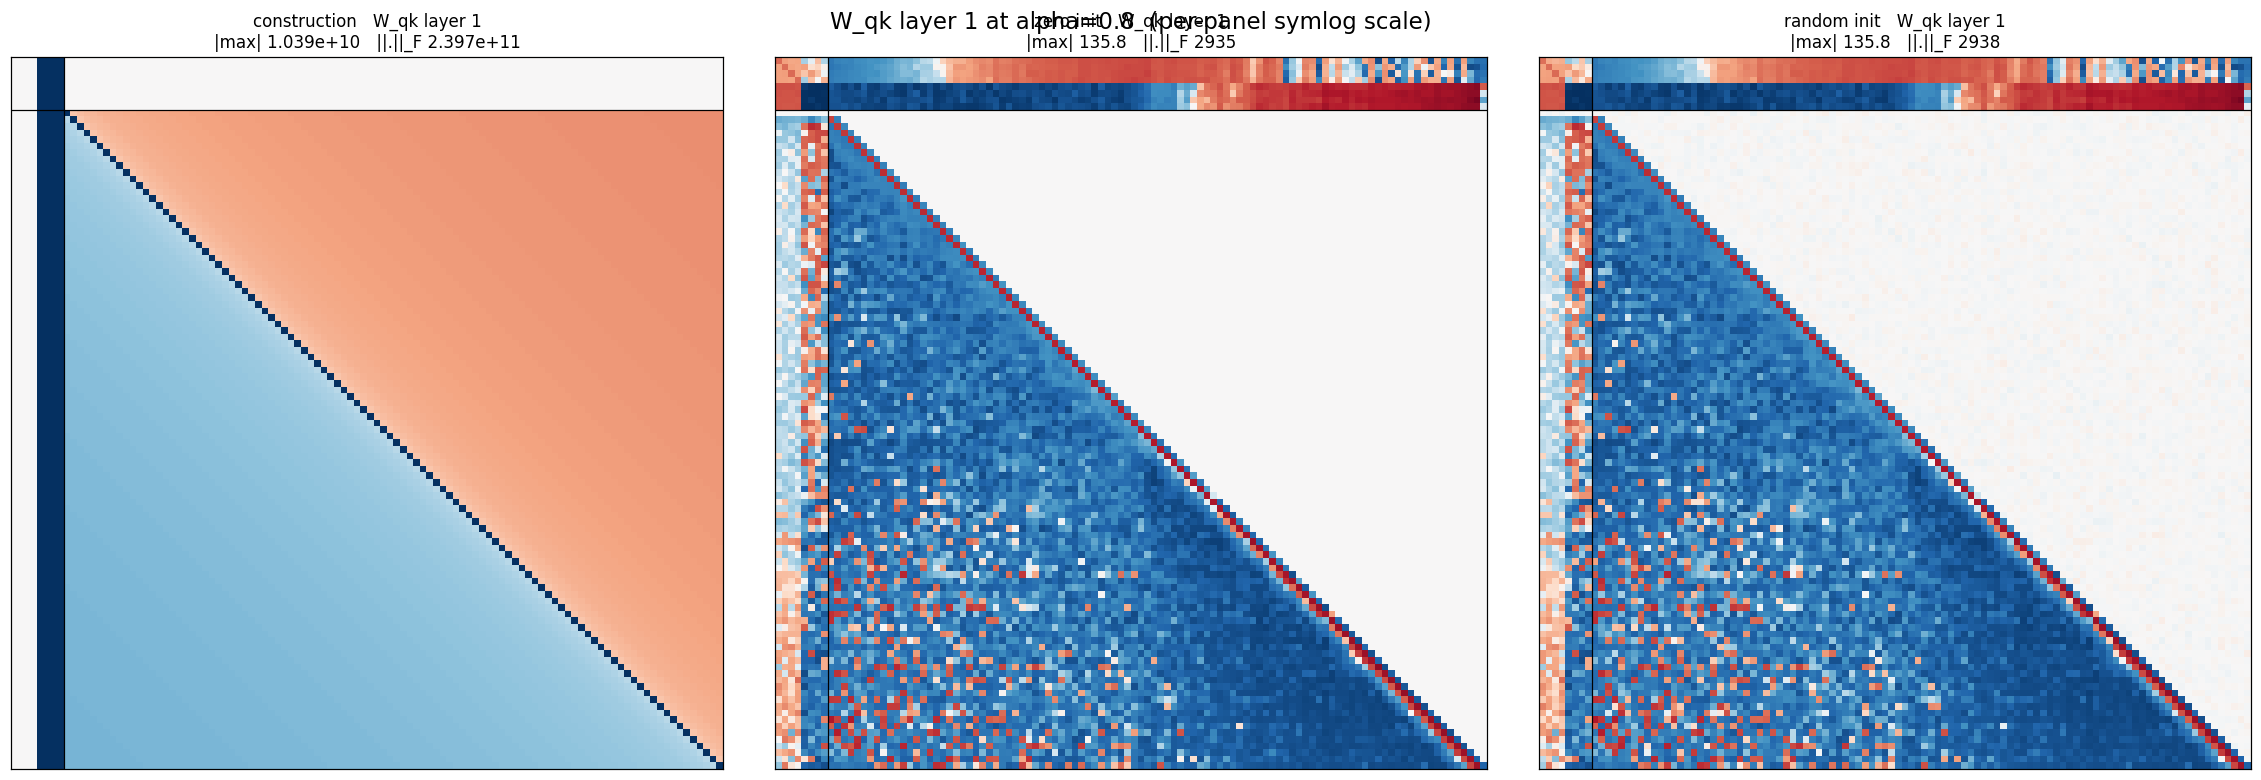

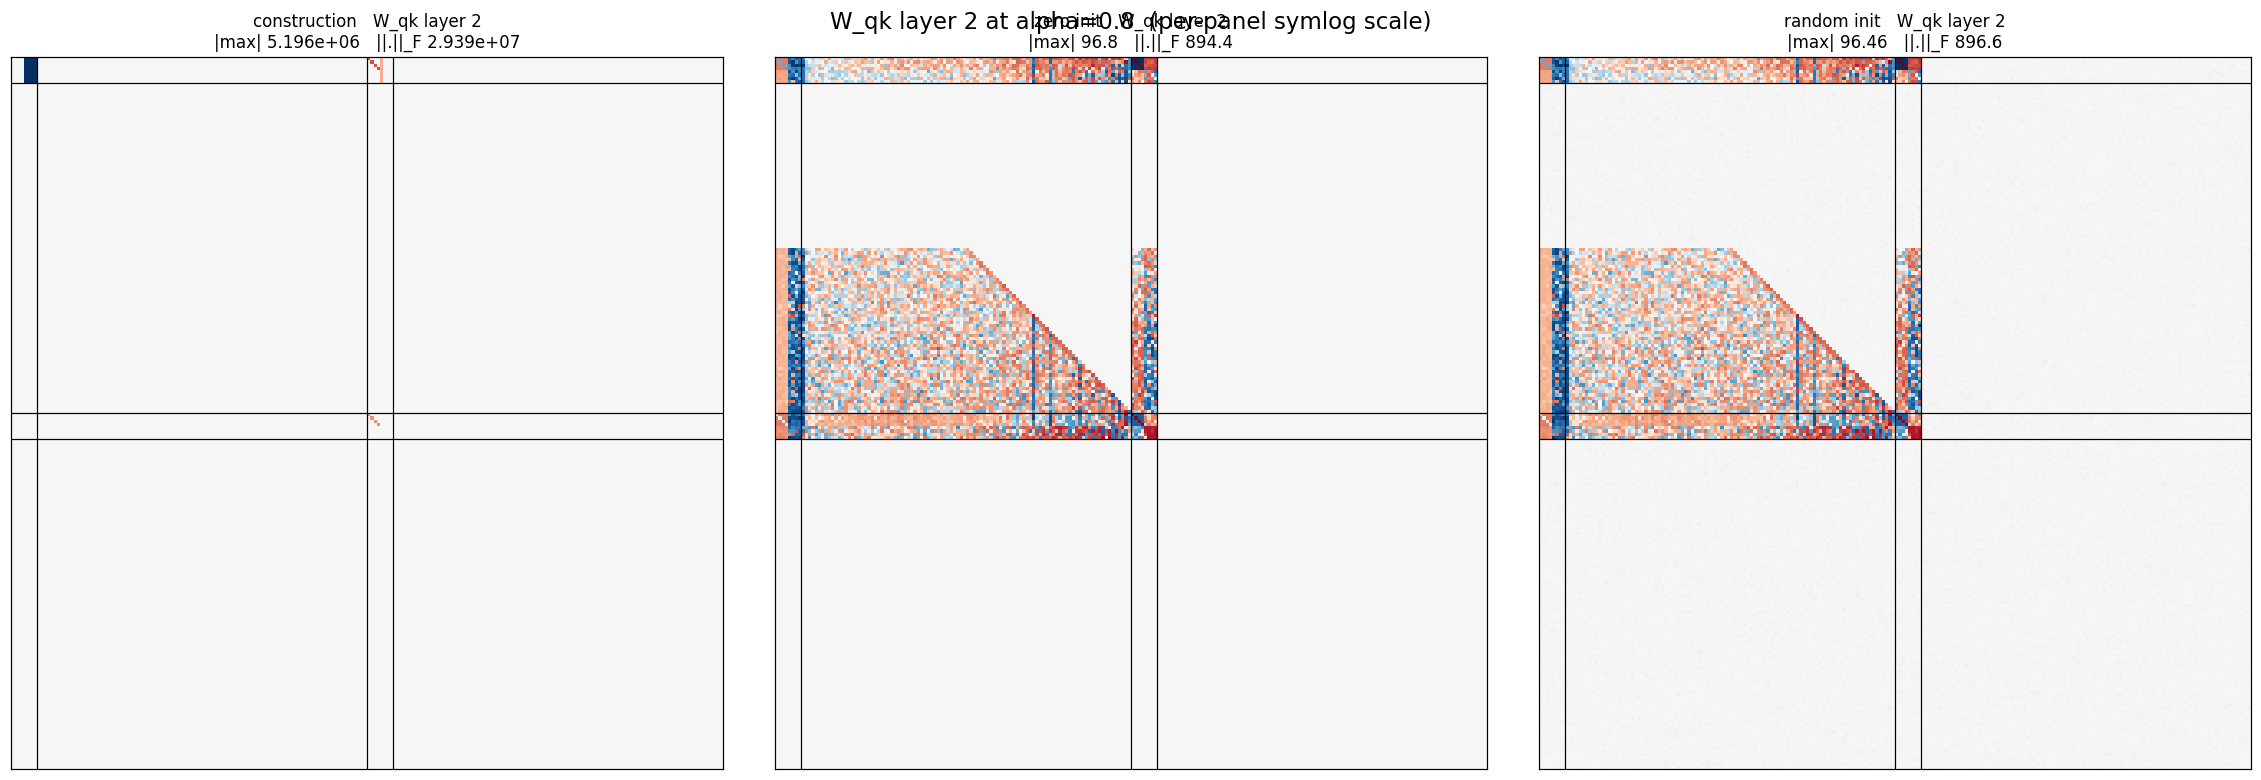

In [6]:
print(f'{"alpha":>6s} {"layer":>6s} {"cos(zero, normal)":>19s} {"cos(zero, constr)":>19s} '
      f'{"cos(normal, constr)":>21s} {"|zero|/|normal|":>16s}')
for t in THRS:
    for li in (0, 1):
        z, n = QK[('zero', t)][li], QK[('normal', t)][li]
        print(f'{t:6.1f} {li+1:6d} {cos(z, n):19.4f} {cos(z, CQK[li]):19.4f} '
              f'{cos(n, CQK[li]):21.4f} {float(z.norm()/n.norm()):16.3f}')
    print()

def bounds(n):
    return [V] if n == D else ([V, D, D + V] if n == IN2 else [])

def show(ax, M, title, lw=0.8):
    A = np.asarray(M.detach() if torch.is_tensor(M) else M, dtype=np.float64)
    a = np.abs(A[A != 0]); v = float(a.max()) if a.size else 1.0
    im = ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
                   norm=SymLogNorm(linthresh=min(1.0, v / 100), linscale=0.6,
                                   vmin=-v, vmax=v, base=10))
    for b in bounds(A.shape[0]):
        ax.axhline(b - .5, color='k', lw=lw)
    for b in bounds(A.shape[1]):
        ax.axvline(b - .5, color='k', lw=lw)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f'{title}\n|max| {np.abs(A).max():.4g}   ||.||_F {np.linalg.norm(A):.4g}',
                 fontsize=11)
    return im

PLOT_THR = 0.8
for li, nm in ((0, 'W_qk layer 1'), (1, 'W_qk layer 2')):
    fig, axes = plt.subplots(1, 3, figsize=(21, 7.2))
    show(axes[0], CQK[li], f'construction   {nm}')
    show(axes[1], QK[('zero', PLOT_THR)][li], f'zero init   {nm}')
    show(axes[2], QK[('normal', PLOT_THR)][li], f'random init   {nm}')
    fig.suptitle(f'{nm} at alpha={PLOT_THR}  (per-panel symlog scale)', fontsize=15)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f'final_wqk{li+1}_a{PLOT_THR}.png'), bbox_inches='tight')
    plt.show()


## 6. The induction block, cell by cell

The $8\times8$ block $W_{qk}^{(2)}[0{:}8,\,108{:}116]$ — own token $\times$ key predecessor. The
construction is $10392.3\,I_4$ plus a $103.9$ trigger in column 4. Every value printed.


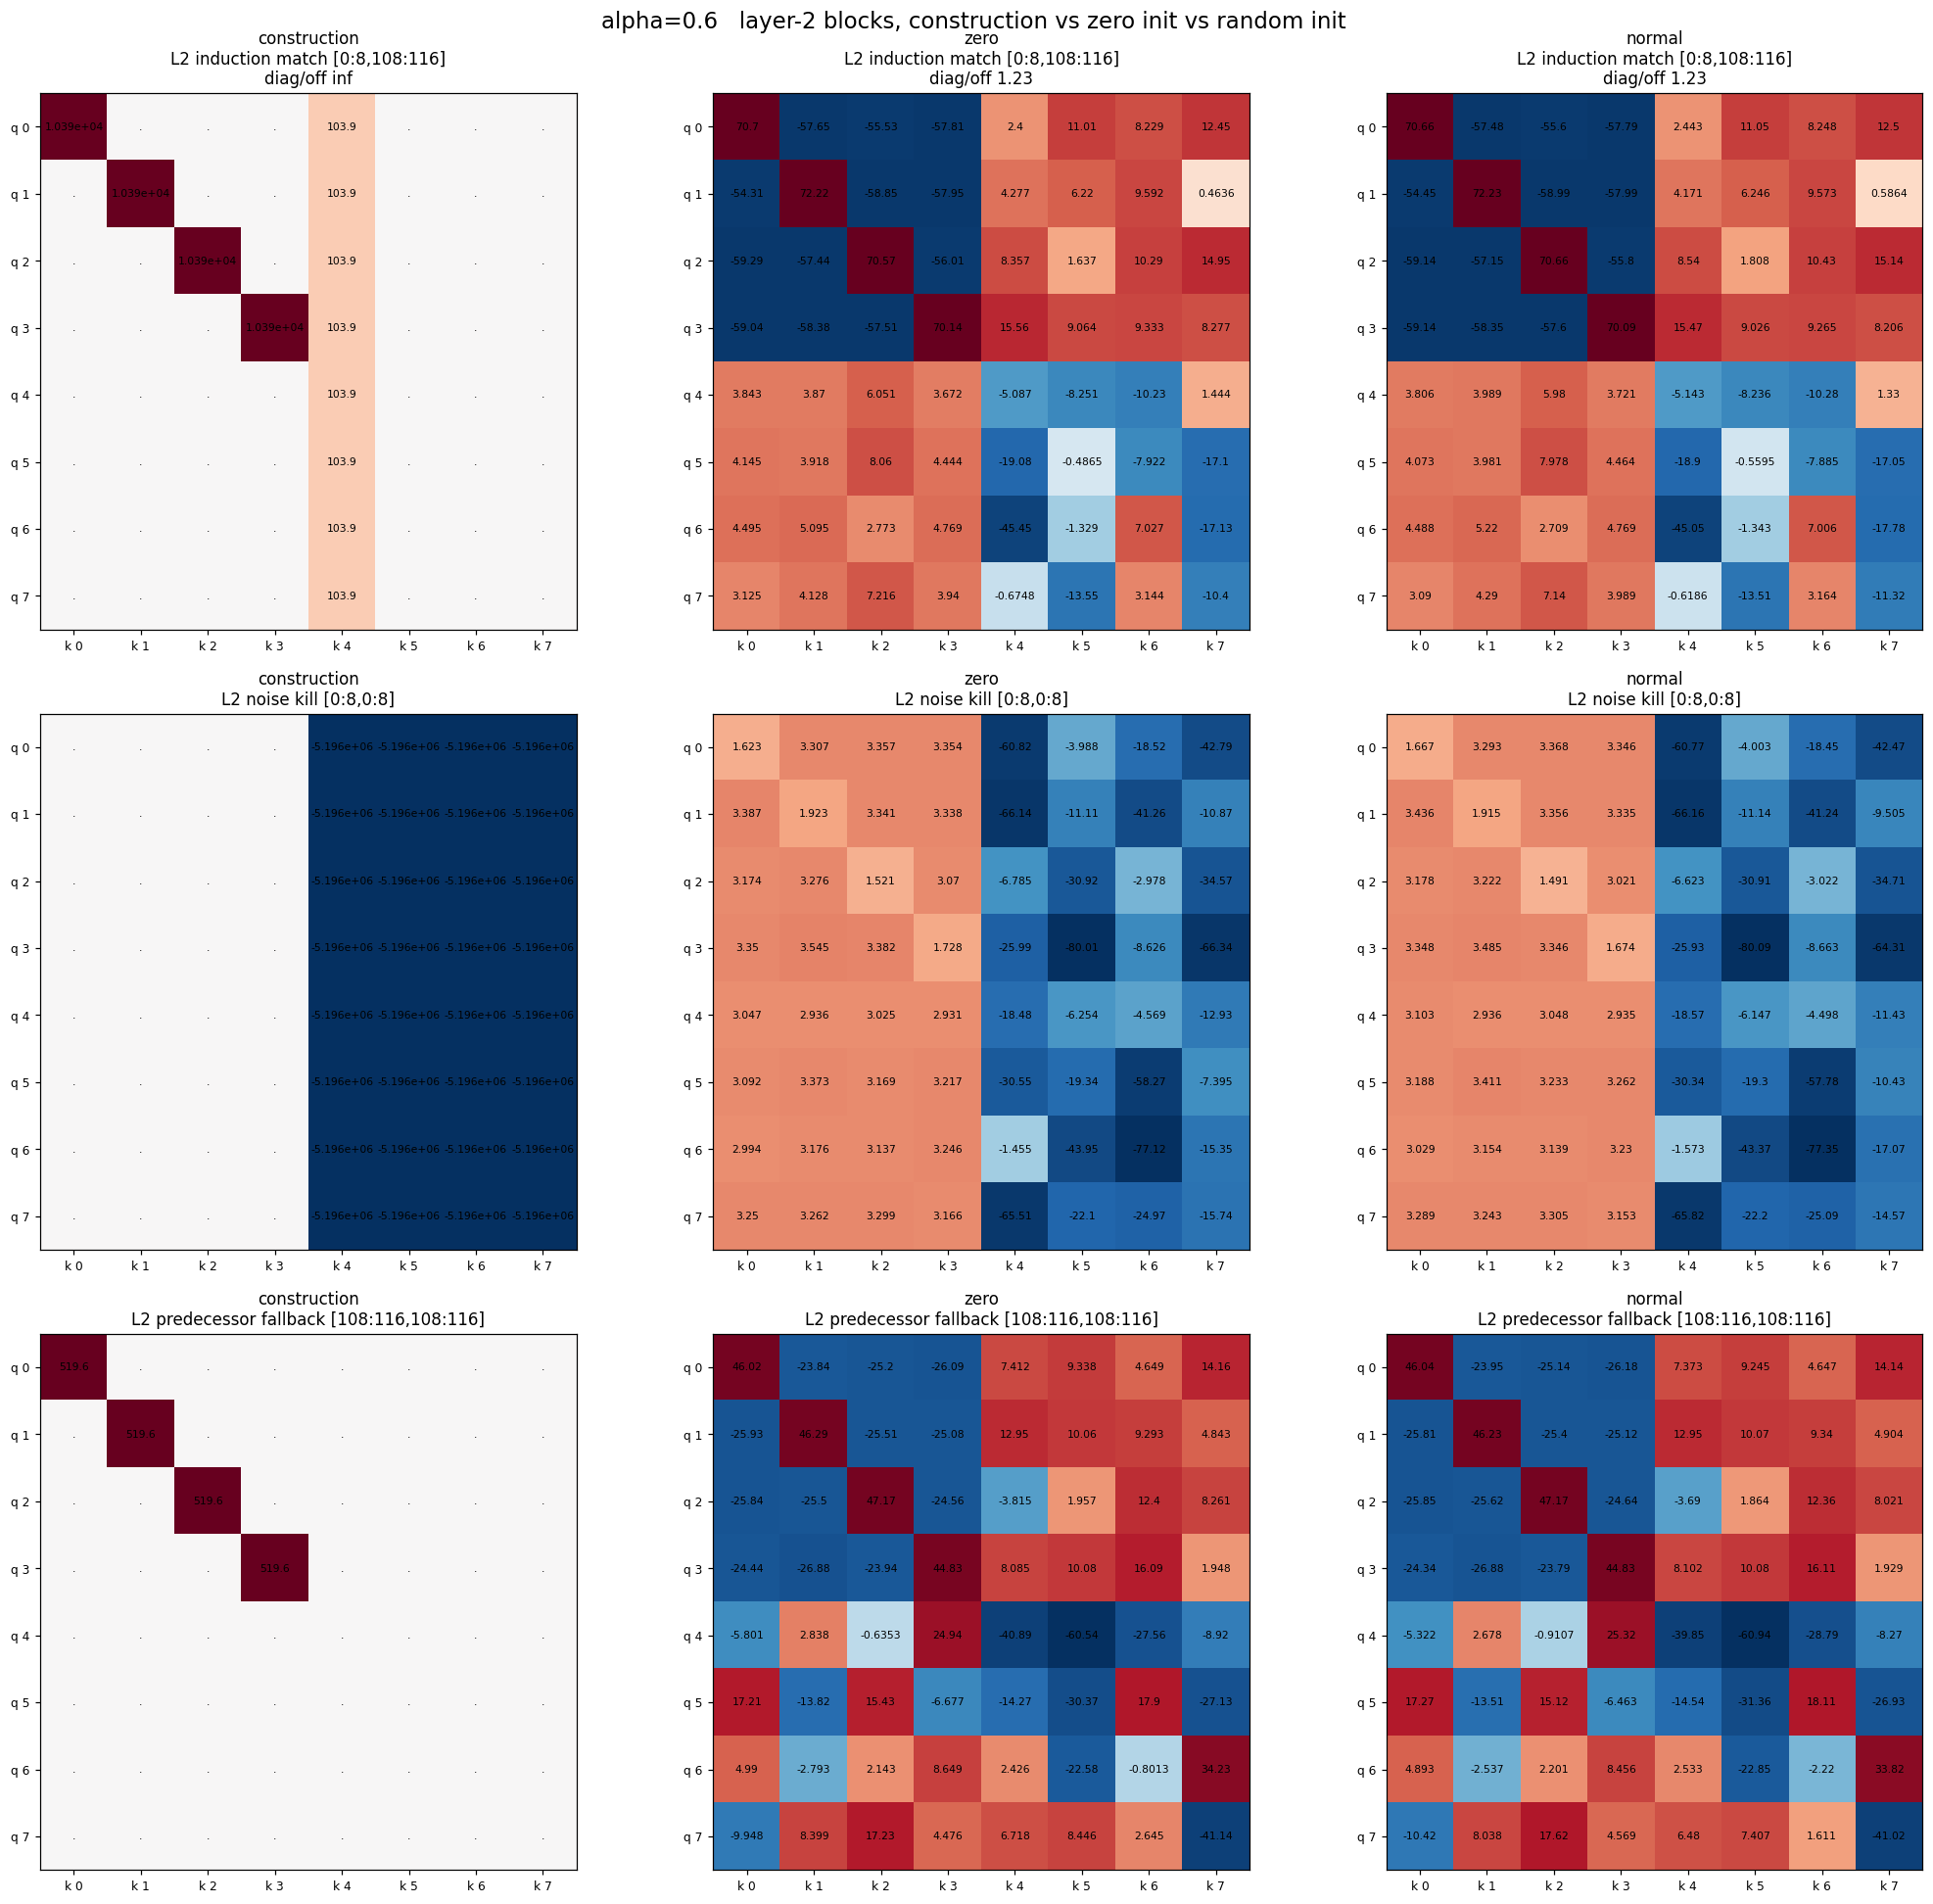

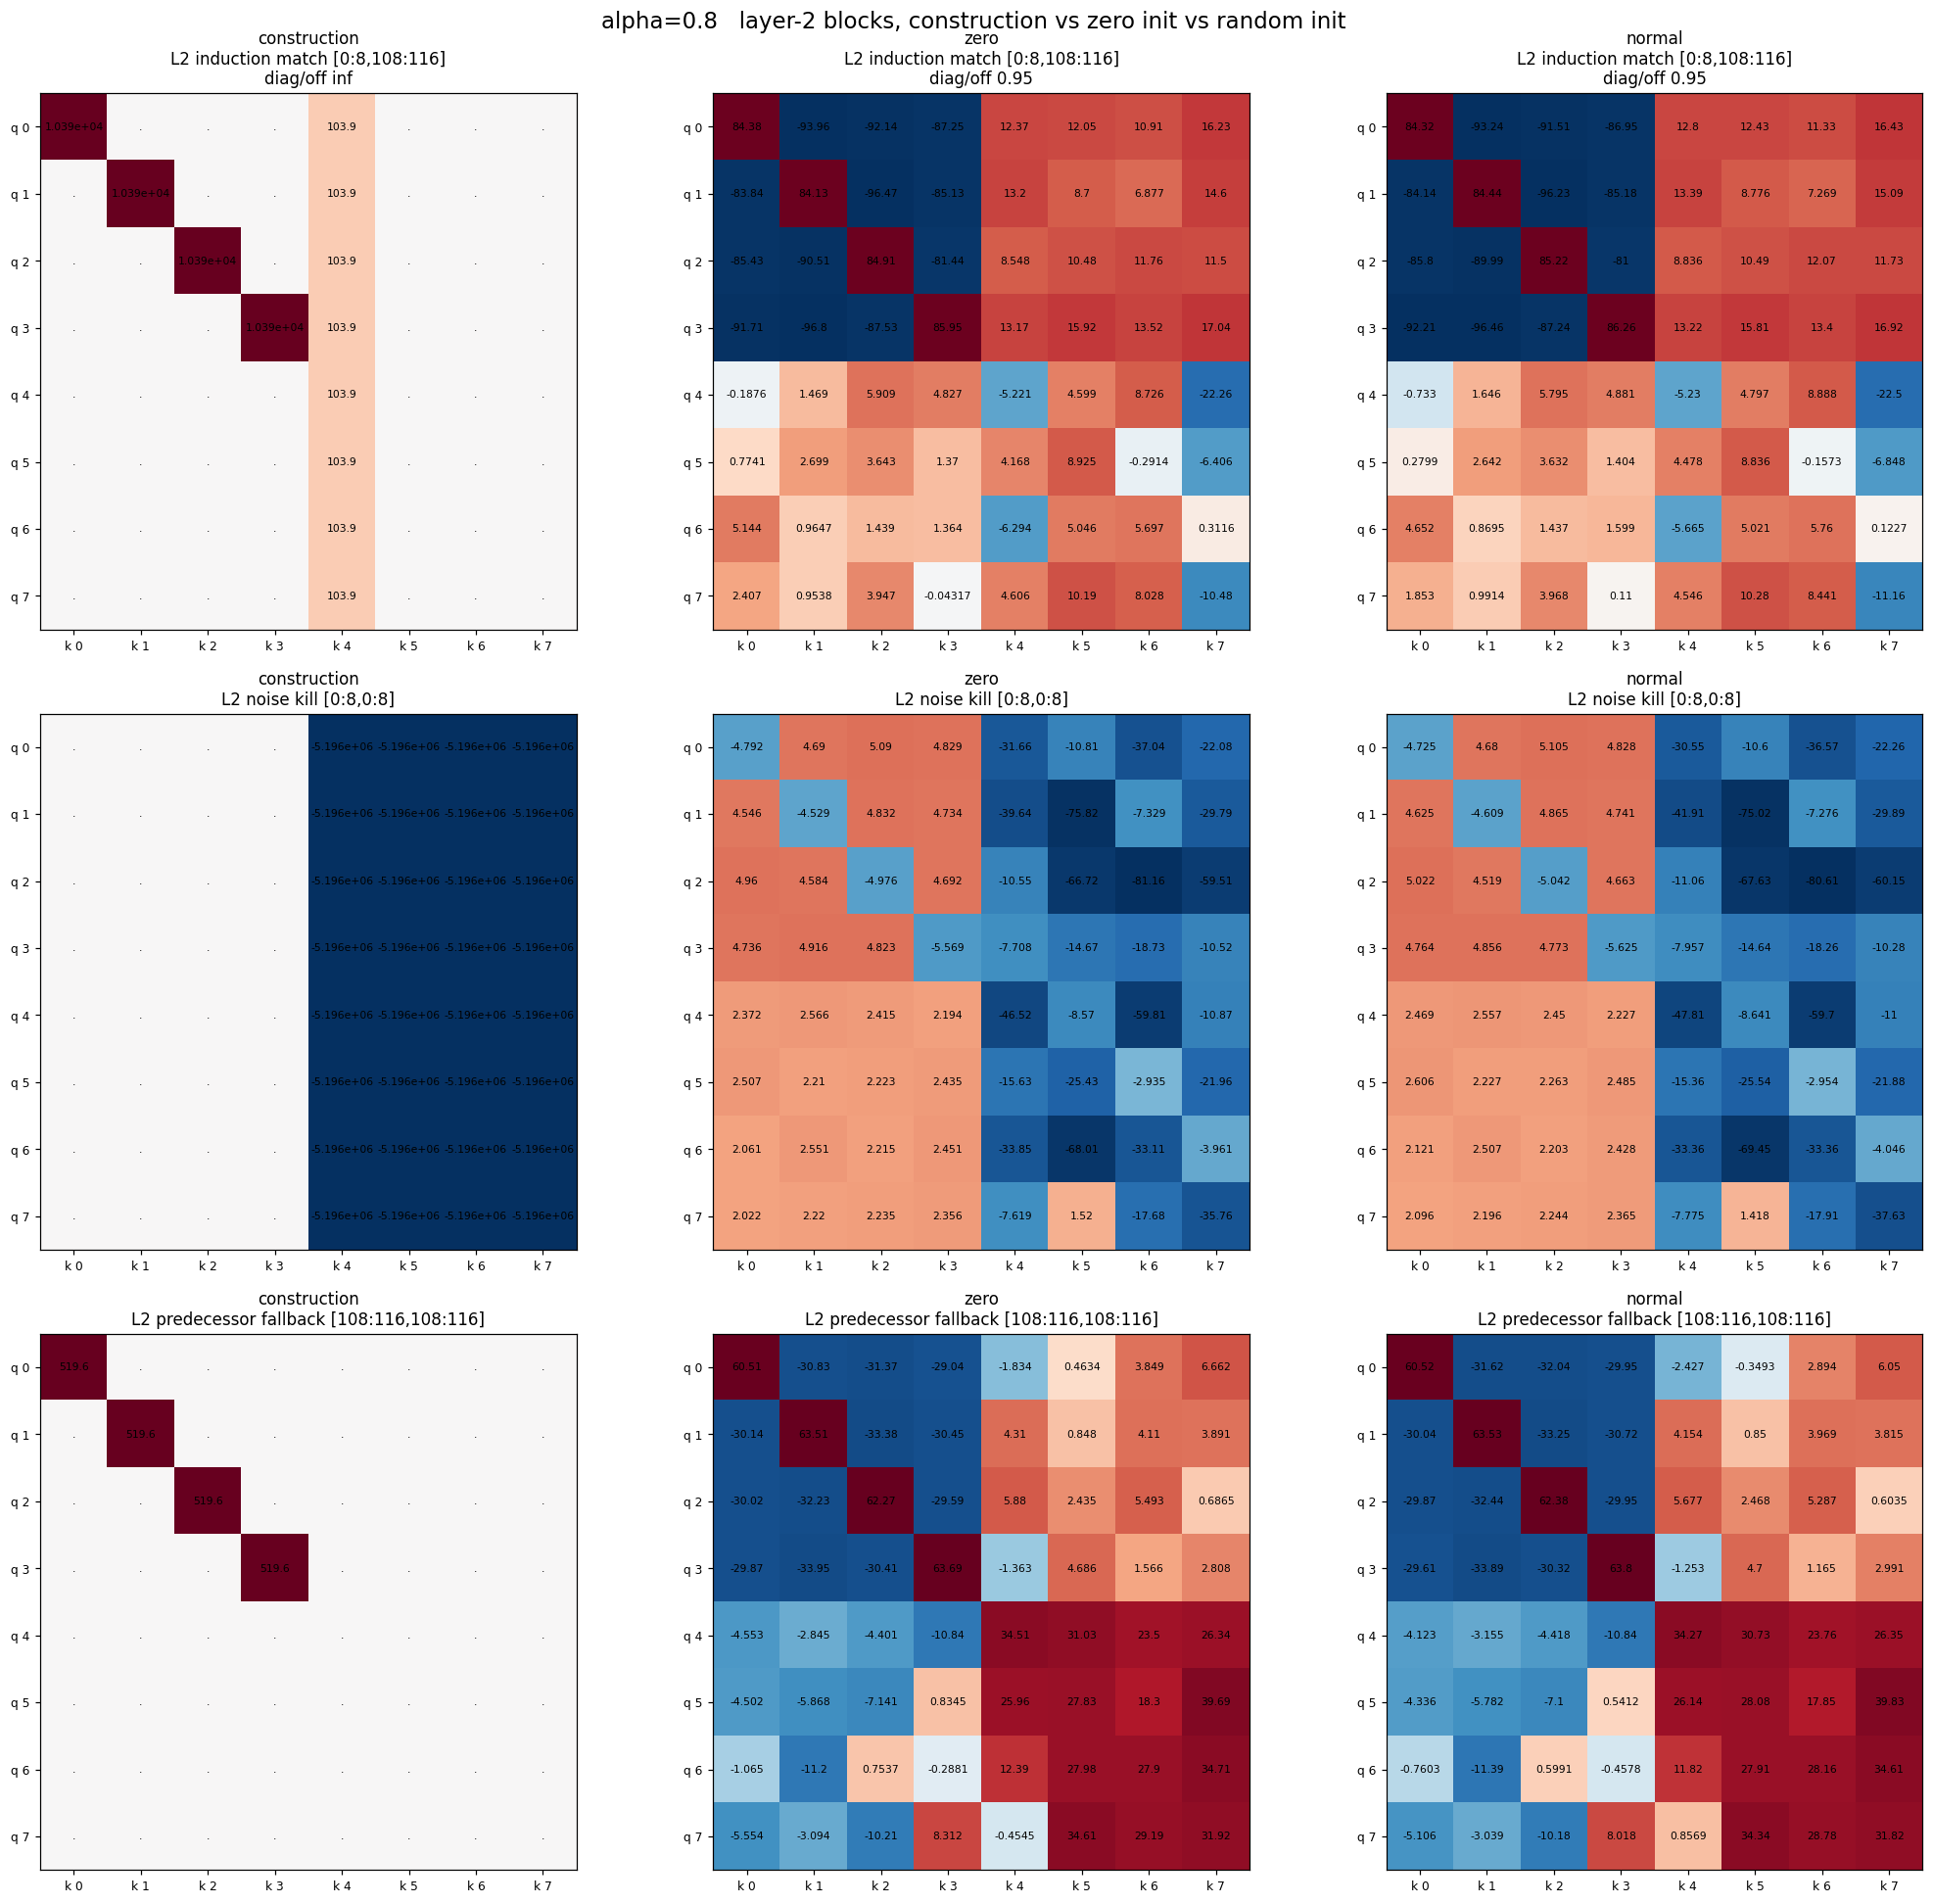

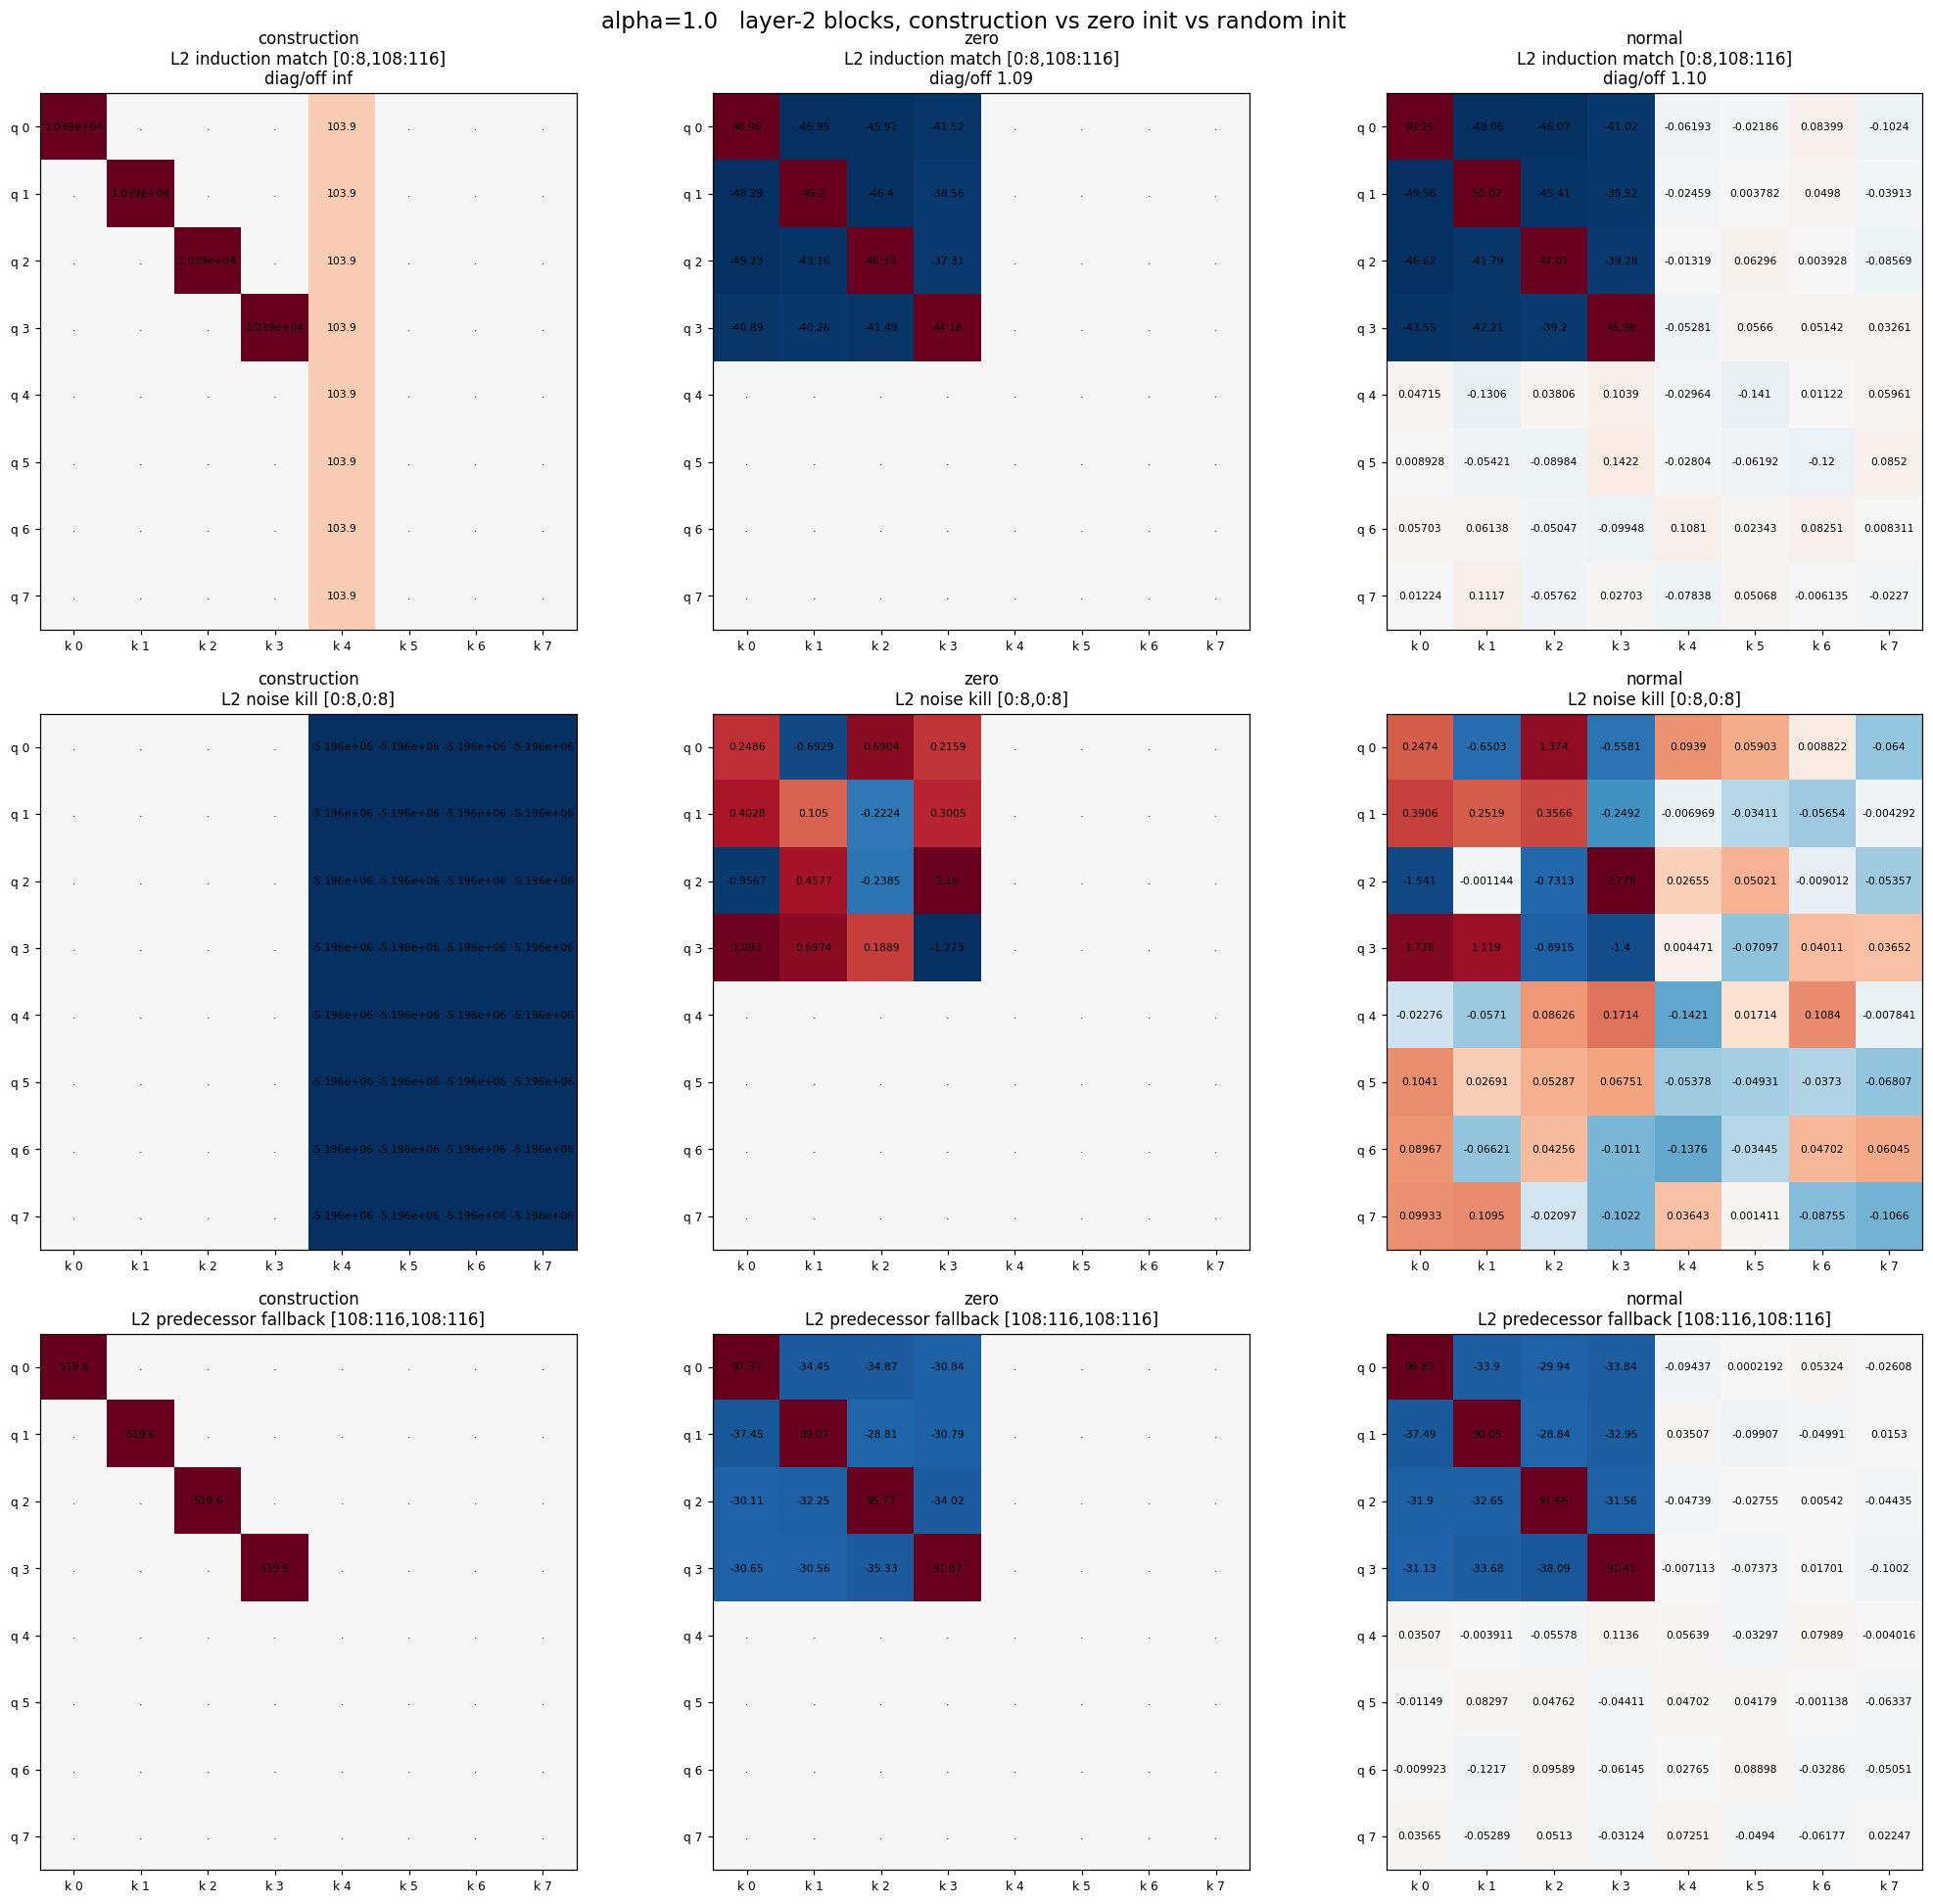

In [7]:
def annot(ax, M, r0, r1, c0, c1, title, rlab, clab, fs=7):
    A = np.asarray(M.detach() if torch.is_tensor(M) else M, dtype=np.float64)[r0:r1, c0:c1]
    a = np.abs(A[A != 0]); v = float(a.max()) if a.size else 1e-30
    ax.imshow(A, cmap='RdBu_r', interpolation='nearest',
              norm=SymLogNorm(linthresh=max(v / 100, 1e-30), linscale=0.6, vmin=-v, vmax=v,
                              base=10))
    for i in range(A.shape[0]):
        for j in range(A.shape[1]):
            ax.text(j, i, f'{A[i, j]:.4g}' if A[i, j] != 0 else '.', ha='center', va='center',
                    fontsize=fs)
    ax.set_xticks(range(A.shape[1])); ax.set_yticks(range(A.shape[0]))
    ax.set_xticklabels(clab, fontsize=8); ax.set_yticklabels(rlab, fontsize=8)
    ax.set_title(title, fontsize=11)

BLK = [('L2 induction match [0:8,108:116]', 1, 0, V, D, D + V),
       ('L2 noise kill [0:8,0:8]',          1, 0, V, 0, V),
       ('L2 predecessor fallback [108:116,108:116]', 1, D, D + V, D, D + V)]
for t in THRS:
    fig, axes = plt.subplots(len(BLK), 3, figsize=(19, 6.0 * len(BLK)))
    for r, (nm, li, r0, r1, c0, c1) in enumerate(BLK):
        panels = [('construction', CQK[li])] + [(lab, QK[(lab, t)][li]) for lab in RUNS]
        for c, (who, M) in enumerate(panels):
            extra = (f'\ndiag/off {diag_off(np.asarray(M)[r0:r1, c0:c1]):.2f}'
                     if 'induction' in nm else '')
            annot(axes[r][c], M, r0, r1, c0, c1, f'{who}\n{nm}{extra}',
                  [f'q {i}' for i in range(r1 - r0)], [f'k {i}' for i in range(c1 - c0)])
    fig.suptitle(f'alpha={t}   layer-2 blocks, construction vs zero init vs random init',
                 fontsize=15)
    fig.tight_layout()
    fig.savefig(os.path.join(FIGDIR, f'blocks_a{t}.png'), bbox_inches='tight')
    plt.show()


## 7. How the zero start breaks symmetry

The first epochs, from an exactly-zero matrix. The layer-1 panel at epoch 0 and epoch 1 must be
identical (the one-step freeze described at the top); the first visible structure in layer 2 is
whatever the very first gradient wrote.


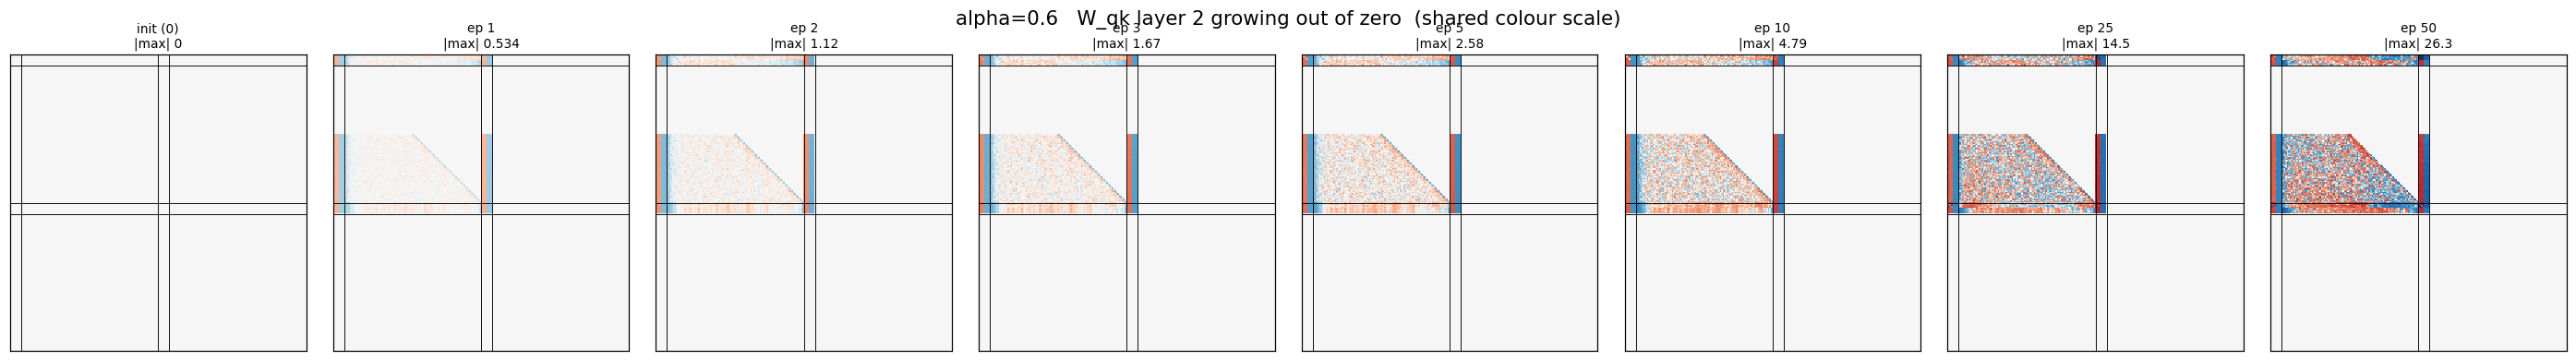

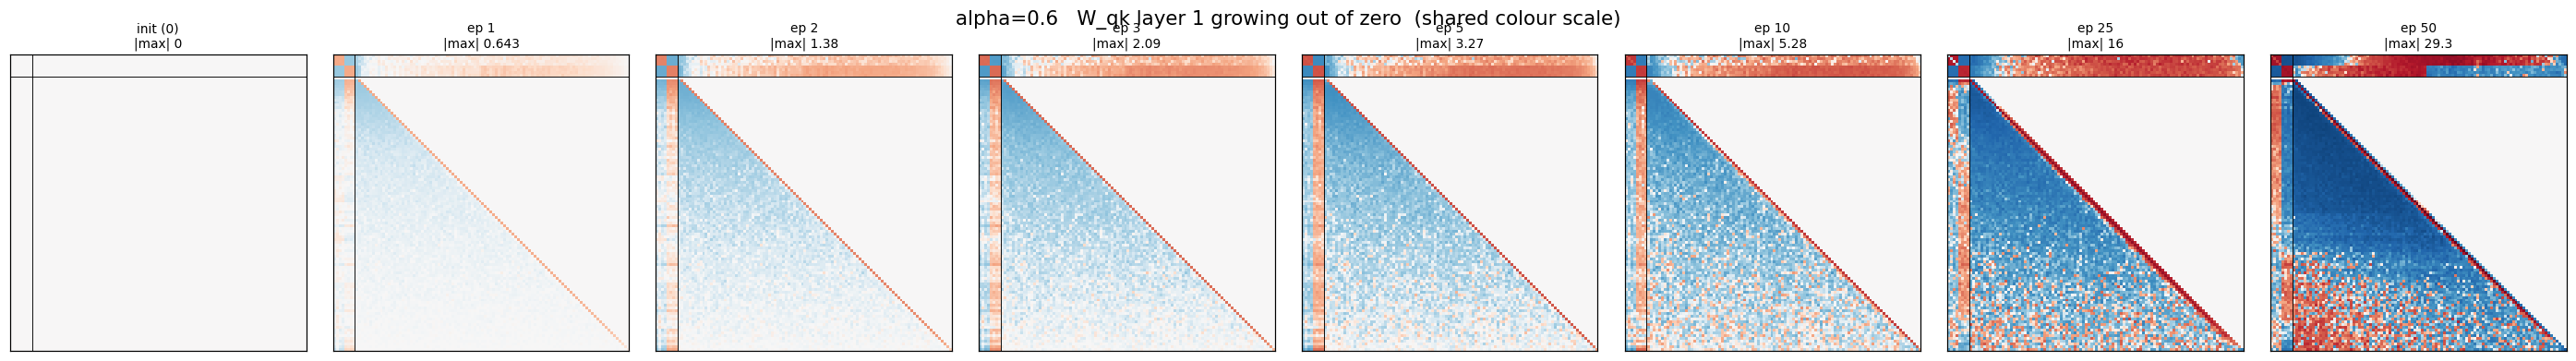

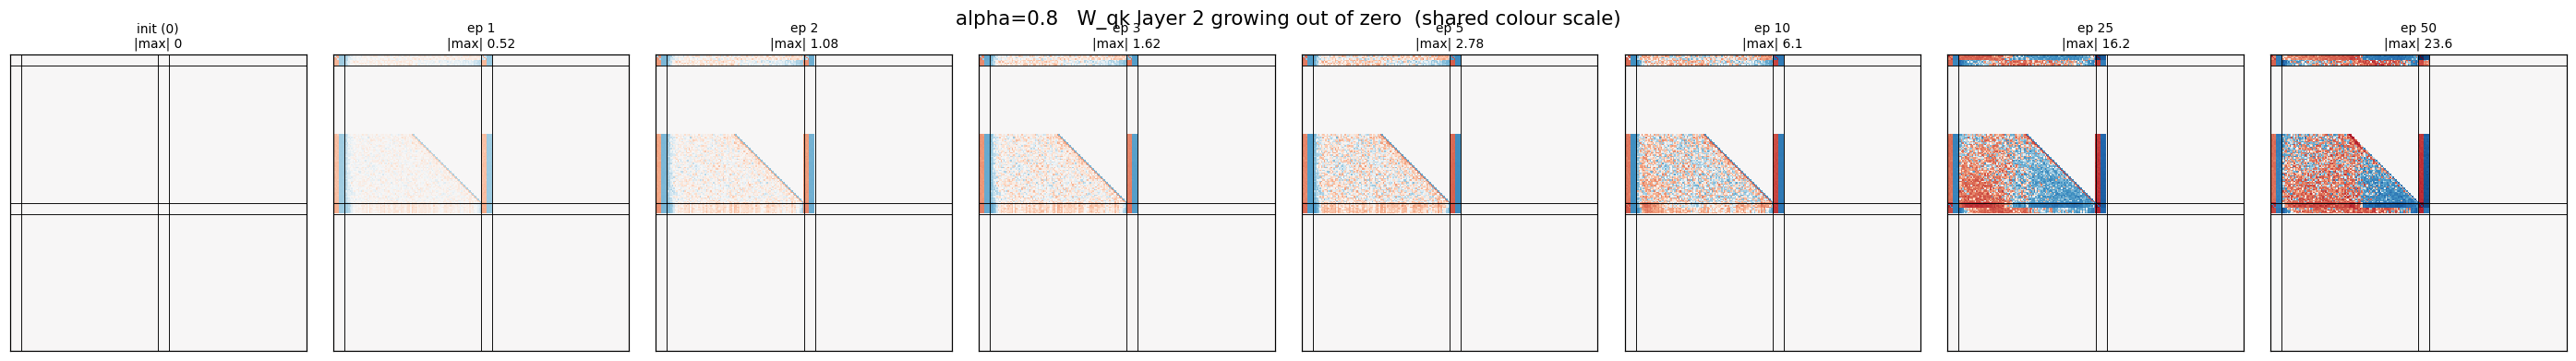

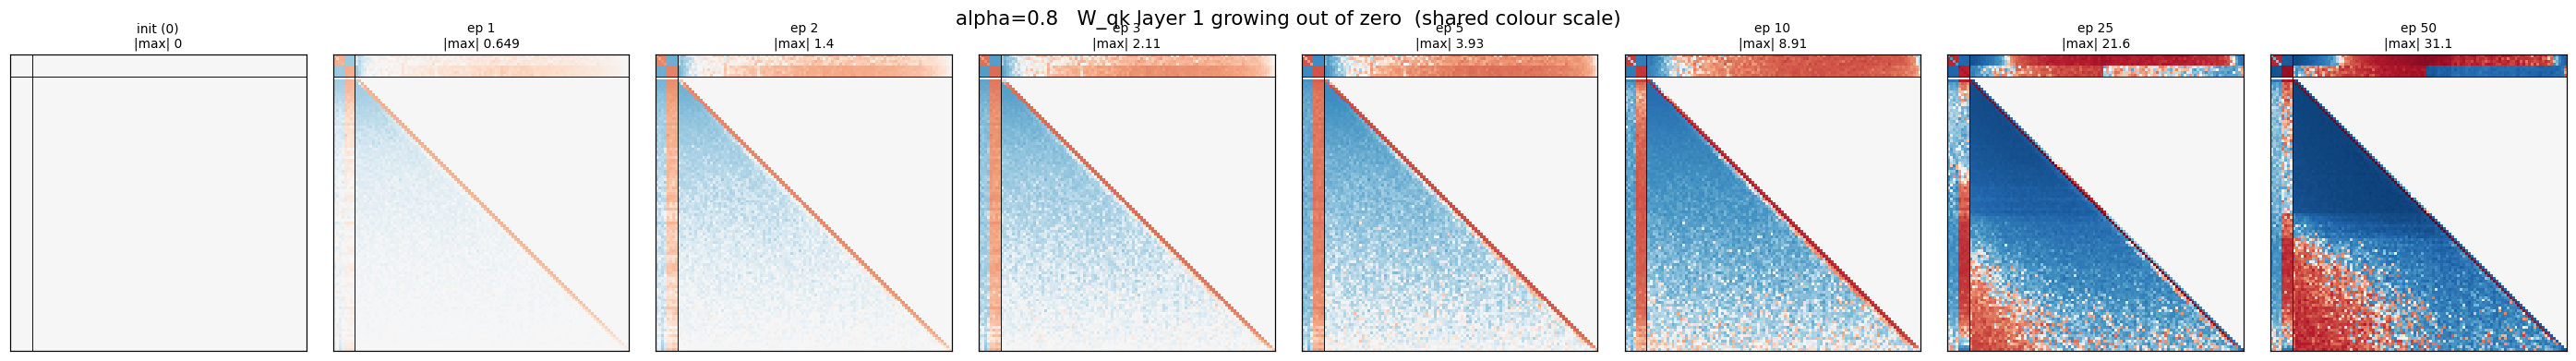

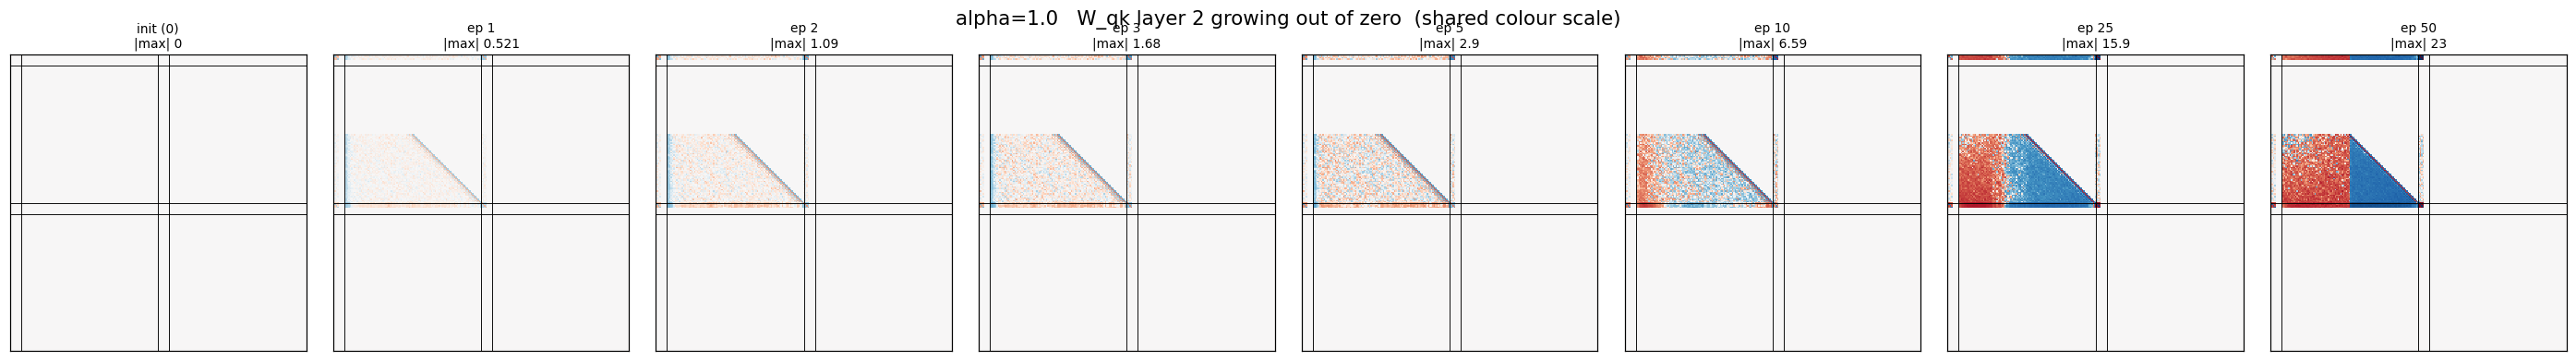

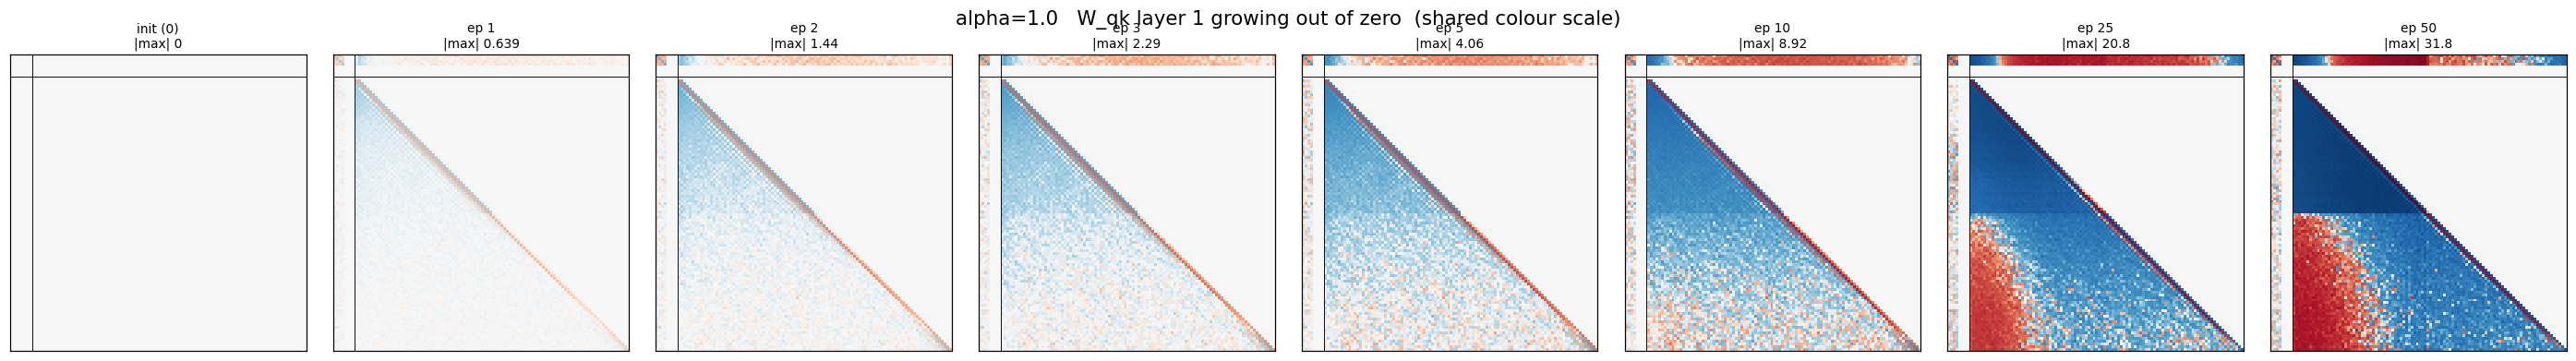

In [8]:
FRAMES = [0, 1, 2, 3, 5, 10, 25, 50]
for t in THRS:
    for li, nm in ((1, 'W_qk layer 2'), (0, 'W_qk layer 1')):
        A = SNAP[('zero', t)][li]
        fr = [e for e in FRAMES if e < A.shape[0]]
        stack = np.asarray(A[fr], dtype=np.float32)
        vf = float(np.abs(stack).max()) or 1e-30
        fig, axes = plt.subplots(1, len(fr), figsize=(3.2 * len(fr), 3.6))
        for k, e in enumerate(fr):
            ax = axes[k]
            ax.imshow(stack[k], cmap='RdBu_r', interpolation='nearest',
                      norm=SymLogNorm(linthresh=max(vf / 100, 1e-30), linscale=0.6,
                                      vmin=-vf, vmax=vf, base=10))
            for b in bounds(stack[k].shape[0]):
                ax.axhline(b - .5, color='k', lw=0.6); ax.axvline(b - .5, color='k', lw=0.6)
            ax.set_xticks([]); ax.set_yticks([])
            ax.set_title(f'{"init (0)" if e == 0 else f"ep {e}"}\n|max| '
                         f'{np.abs(stack[k]).max():.3g}', fontsize=9)
        fig.suptitle(f'alpha={t}   {nm} growing out of zero  (shared colour scale)', fontsize=14)
        fig.tight_layout()
        fig.savefig(os.path.join(FIGDIR, f'growth_wqk{li+1}_a{t}.png'), bbox_inches='tight')
        plt.show()


## 8. What to take from this

* **Section 2 is the headline.** Same final CE means the zero start is harmless and the solution
  is not an artefact of a lucky random draw. A gap means the initialization picks the basin.
* **Section 4 is the structural test.** The construction's layer-2 support is 0.41% of the
  matrix. Where GD puts its mass, starting from literally nothing, is the cleanest statement
  available about what the loss actually wants — there is no initial noise for it to inherit.
* **Section 5 asks whether the two runs agree with each other**, not just with the loss. High
  `cos(zero, normal)` with different norms still counts as the same solution: $W_{qk}$ carries a
  temperature gauge, and only the softmax ordering matters.
* **Section 7 shows symmetry breaking.** Layer 1 is frozen for one step by construction; whatever
  appears in layer 2 at epoch 1 is written by a single gradient evaluated at an exactly symmetric
  point, so it is the loss's own preferred direction with no random component at all.
* If `induction_diag_off` stays near 1 here as it did in the random-init run, that rules out
  "the random init hid the diagonal" as an explanation — both starts would be failing to build it
  for the same reason.
